# Домашнее задание. Нейросетевая классификация текстов

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

In [15]:
!pip install -q datasets

Импорт необходимых библиотек

In [16]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List
import string

import seaborn
seaborn.set(palette='summer')

In [17]:
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [18]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [19]:
# Загрузим датасет
dataset = datasets.load_dataset('ag_news')

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

In [20]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    # Приводим к нижнему регистру и убираем пунктуацию
    prccessed_text = example.lower().translate(
        str.maketrans('', '', string.punctuation))

    for word in word_tokenize(prccessed_text):
        words[word] += 1


vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
counter_threshold = 25

for char, cnt in words.items():
    if cnt > counter_threshold:
        vocab.add(char)

print(f'Размер словаря: {len(vocab)}')

word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

  0%|          | 0/120000 [00:00<?, ?it/s]

Размер словаря: 11842


In [21]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(
            str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [
            word2ind.get(word, self.unk_id) for word in word_tokenize(processed_text)
            ]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [22]:
train_dataset = WordDataset(dataset['train'])

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])), 5000)
eval_dataset = WordDataset(dataset['test'].select(idx))

batch_size = 32
train_dataloader = DataLoader(
    train_dataset, shuffle=True, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, shuffle=False, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [23]:
def evaluate(model, eval_dataloader):
    model.eval()
    preds = []
    labels = []

    with torch.no_grad():
        for batch in tqdm(eval_dataloader, desc="Evaluating"):
            logits = model(batch['input_ids'])
            pred = logits.argmax(dim=1)

            preds.append(pred)
            labels.append(batch['label'])

    preds = torch.cat(preds)
    labels = torch.cat(labels)

    acc = (preds == labels).float().mean().item()
    return acc

## Ход работы
Оценка за домашнее задание складывается из четырех частей:
### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

# архитектура модели

ЭКСПЕРИМЕНТ 1

In [24]:
class RNNClassifier(nn.Module):
  def __init__(self, hidden_dim: int, vocab_size: int, num_classes: int = 4, # меняем кол-во классов (в коде из семинара было 2)
               aggregation_type: str = 'max'):
    super().__init__() # наследуем методы nn.Module
    self.embedding = nn.Embedding(vocab_size, hidden_dim) # эмбеддинги размером vocab_size X hidden_dim

    # hidden_dim X hidden_dim, batch_first=True означает порядок измерений
    # последовательностей [batch_size, seq_len, feature_dim]
    self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True)
    self.linear = nn.Linear(hidden_dim, hidden_dim) # hidden_dim X hidden_dim

    # проекция в пространство классов, в нашем случае превращаем вектор
    # размера 256 в вектор размера 4, столько, сколько и классов
    self.projection = nn.Linear(hidden_dim, num_classes)
    self.non_lin = nn.Tanh()
    self.dropout = nn.Dropout(p=0.1)

    self.aggregation_type = aggregation_type


  def forward(self, input_batch) -> torch.Tensor:
    embeddings = self.embedding(input_batch)

    # считаем скрытое состояние на каждом шаге последовательности
    output, _ = self.rnn(embeddings)

    if self.aggregation_type == 'max':
      output = output.max(dim=1)[0]
    elif self.aggregation_type == 'mean':
      output = output.mean(dim=1)
    else:
      raise ValueError("Invalid aggregation_type")
    output = self.dropout(self.linear(self.non_lin(output)))
    prediction = self.projection(self.non_lin(output)) # и это что, зачем нам projection, какой у него смысл в данном классе

    return prediction


In [25]:
num_epoch = 5
eval_steps = len(train_dataloader) // 2

losses_type = {}
acc_type = {}

for aggregation_type in ['max', 'mean']:
  print(f"тип: {aggregation_type}")
  losses = []
  acc = []

  model = RNNClassifier(
      hidden_dim=256, vocab_size=len(word2ind), aggregation_type=aggregation_type
  ).to(device)

  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

  for epoch in range(num_epoch):
    epoch_losses = []
    model.train()
    for i, batch in enumerate(tqdm(train_dataloader, desc=f'эпоха: {epoch}:')):
      optimizer.zero_grad()
      logits = model(batch['input_ids'])
      loss = criterion(logits, batch['label'])
      loss.backward()
      optimizer.step()

      epoch_losses.append(loss.item())
      if i % eval_steps == 0 and i > 0:
        model.eval()
        acc_val = evaluate(model, eval_dataloader)
        print(f"  [Шаг {i}] loss: {loss.item():.4f}, acc: {acc_val:.4f}")
        model.train()

    avg_loss = sum(epoch_losses) / len(epoch_losses)
    losses.append(avg_loss)
    model.eval()
    epoch_acc = evaluate(model, eval_dataloader)
    acc.append(epoch_acc)
    model.train()

    print(f"Эпоха {epoch+1}/{num_epoch} | Средний loss: {avg_loss:.4f} | Acc: {epoch_acc:.4f}")

  losses_type[aggregation_type] = losses
  acc_type[aggregation_type] = acc

тип: max


эпоха: 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

  [Шаг 1875] loss: 0.3305, acc: 0.8774


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Эпоха 1/5 | Средний loss: 0.4035 | Acc: 0.8870


... (41 outputs left out)

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

  [Шаг 1875] loss: 0.0411, acc: 0.9094


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Эпоха 5/5 | Средний loss: 0.1584 | Acc: 0.9026


ЭКСПЕРИМЕНТ 2 (GRU)

In [26]:
class GRUClassifier(nn.Module):
  def __init__(self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
               aggregation_type: str='max'):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, hidden_dim, padding_idx=word2ind['<pad>'])
    self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
    self.linear = nn.Linear(hidden_dim, hidden_dim)
    self.projection = nn.Linear(hidden_dim, num_classes)

    self.non_lin = nn.Tanh()
    self.dropout = nn.Dropout(p=0.1)

    self.aggregation_type = aggregation_type

  def forward(self, input_batch) -> torch.Tensor:
    mask = (input_batch != word2ind['<pad>'])
    embeddings = self.embedding(input_batch)
    output, _ = self.rnn(embeddings)

    # if self.aggregation_type == 'max':
    #   output = output.max(dim=1)[0]
    # elif self.aggregation_type == 'mean':
    #   output = output.mean(dim=1)
    # else:
    #   raise ValueError("Invalid aggregation_type")
    if self.aggregation_type == 'max':
        output = output.masked_fill(~mask.unsqueeze(-1), float('-inf'))
        output = output.max(dim=1)[0]

    elif self.aggregation_type == 'mean':
        masked_output = output * mask.unsqueeze(-1)
        output = masked_output.sum(dim=1) / mask.sum(dim=1, keepdim=True).clamp(min=1)

    else:
        raise ValueError("Invalid aggregation_type")

    output = self.dropout(self.linear(self.non_lin(output)))
    prediction = self.projection(self.non_lin(output))

    return prediction

In [27]:
num_epoch = 5
eval_steps = len(train_dataloader) // 2

print("GRU")

gru_losses = []
gru_acc = []

model = GRUClassifier(
    hidden_dim=256, vocab_size=len(word2ind), aggregation_type='max'
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

best_gru_acc = 0.0
best_gru_state = None

for epoch in range(num_epoch):
  model.train()
  epoch_losses = []
  for i, batch in enumerate(tqdm(train_dataloader, desc=f'эпоха: {epoch}:')):
    optimizer.zero_grad()
    logits = model(batch['input_ids'])
    loss = criterion(logits, batch['label'])

    loss.backward()
    optimizer.step()

    epoch_losses.append(loss.item())

    if i % eval_steps == 0:
      model.eval()
      current_acc = evaluate(model, eval_dataloader)
      gru_acc.append(current_acc)
      print(f"эпоха {epoch}, шаг {i}: eval_acc = {current_acc:.4f}")
      if current_acc > best_gru_acc:
        best_gru_acc = current_acc
        best_gru_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

      model.train()

  gru_losses.append(sum(epoch_losses) / len(epoch_losses))
print(f'Best GRU accuracy: {best_gru_acc:.4f}')

GRU


эпоха: 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 0, шаг 0: eval_acc = 0.2470


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 0, шаг 1875: eval_acc = 0.8882


... (6 outputs left out)

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 2, шаг 0: eval_acc = 0.9006


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 2, шаг 1875: eval_acc = 0.9012
Best GRU accuracy: 0.9142


In [28]:
results = {}

# Лучший результат среди RNN max/mean
for aggregation_type, scores in acc_type.items():
    results[f'RNN + {aggregation_type}'] = max(scores)

# Лучший результат GRU
results['GRU + max'] = best_gru_acc

print("лучшие результаты моделей:")
for model_name, score in results.items():
    print(f"{model_name}: {score:.4f}")

best_model_name = max(results, key=results.get)
best_score = results[best_model_name]

print()
print(f"лучшая модель: {best_model_name}")
print(f"лучший score: {best_score:.4f}")

лучшие результаты моделей:
RNN + max: 0.9110
RNN + mean: 0.9102
GRU + max: 0.9142

лучшая модель: GRU + max
лучший score: 0.9142


In [29]:
best_model = GRUClassifier(
    hidden_dim=256, vocab_size=len(word2ind), aggregation_type='max'
).to(device)

best_model.load_state_dict(best_gru_state)
best_model.eval()

final_score = evaluate(best_model, eval_dataloader)
print(f'{final_score:.4f}')

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

0.9142


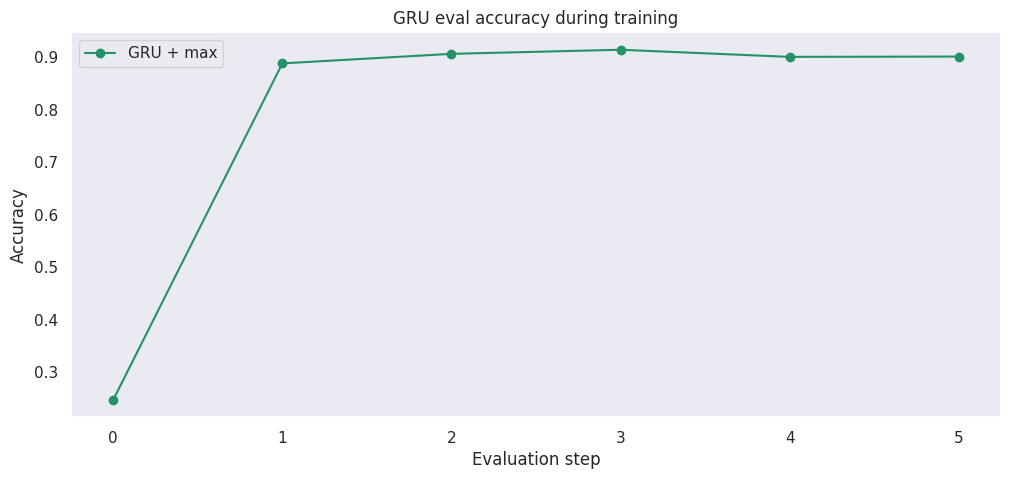

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(gru_acc, marker='o', label='GRU + max')
plt.title("GRU eval accuracy during training")
plt.xlabel("Evaluation step")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [34]:
num_epoch = 5
eval_steps = len(train_dataloader) // 2

print("GRU")

gru_losses = []
gru_acc = []

model = GRUClassifier(
    hidden_dim=256, vocab_size=len(word2ind), aggregation_type='mean'
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

best_gru_acc = 0.0
best_gru_state = None

for epoch in range(num_epoch):
  model.train()
  epoch_losses = []
  for i, batch in enumerate(tqdm(train_dataloader, desc=f'эпоха: {epoch}:')):
    optimizer.zero_grad()
    logits = model(batch['input_ids'])
    loss = criterion(logits, batch['label'])

    loss.backward()
    optimizer.step()

    epoch_losses.append(loss.item())

    if i % eval_steps == 0:
      model.eval()
      current_acc = evaluate(model, eval_dataloader)
      gru_acc.append(current_acc)
      print(f"эпоха {epoch}, шаг {i}: eval_acc = {current_acc:.4f}")
      if current_acc > best_gru_acc:
        best_gru_acc = current_acc
        best_gru_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

      model.train()

  gru_losses.append(sum(epoch_losses) / len(epoch_losses))
print(f'Best GRU accuracy: {best_gru_acc:.4f}')

GRU


эпоха: 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 0, шаг 0: eval_acc = 0.2482


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 0, шаг 1875: eval_acc = 0.8938


... (16 outputs left out)

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 4, шаг 0: eval_acc = 0.9090


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

эпоха 4, шаг 1875: eval_acc = 0.9108
Best GRU accuracy: 0.9162


In [40]:
results = {}

# Лучший результат среди RNN max/mean
for aggregation_type, scores in acc_type.items():
    results[f'RNN + {aggregation_type}'] = max(scores)

# Лучший результат GRU
results['GRU + mean'] = best_gru_acc

print("лучшие результаты моделей:")
for model_name, score in results.items():
    print(f"{model_name}: {score:.4f}")

best_model_name = max(results, key=results.get)
best_score = results[best_model_name]

print()
print(f"лучшая модель: {best_model_name}")
print(f"лучший score: {best_score:.4f}")

лучшие результаты моделей:
RNN + max: 0.9110
RNN + mean: 0.9102
GRU + mean: 0.9162

лучшая модель: GRU + mean
лучший score: 0.9162


In [39]:
best_model = GRUClassifier(
    hidden_dim=256, vocab_size=len(word2ind), aggregation_type='mean'
).to(device)

best_model.load_state_dict(best_gru_state)
best_model.eval()

final_score = evaluate(best_model, eval_dataloader)
print(f'{final_score:.4f}')

Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

0.9162


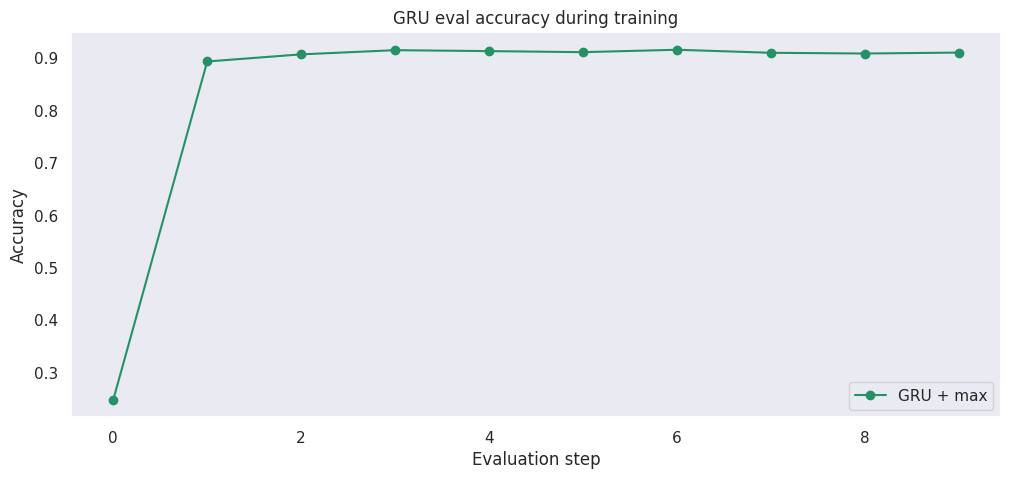

In [37]:
plt.figure(figsize=(12, 5))
plt.plot(gru_acc, marker='o', label='GRU + max')
plt.title("GRU eval accuracy during training")
plt.xlabel("Evaluation step")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# итог

в ходе работы. была обучена обычная рекуррентная нейронная сеть для классификации категории новостей из датасета AG News, а также проведены 3 эксперимента по ее улучшению.

в качестве первого эксперимента было использовано влияние способа агрегации скрытых состояний модели. были использованы: **max-pooling, mean-pooling.** из сравнения стало понятно, что агрегация влияет на качество модели. когда значение accuracy у max-pooling'а -- 0.9110, у mean-pooling'а -- 0.9102.

во втором эксперименте простая RNN модель была заменена на GRU. эта улучшенная архитектура показала большее качество, так как она позволяет эффективно справляться с проблемой забывания начала последовательности обычной рнн и сохраняет важную информацию по ходу текста. accuracy GRU + max-pooling составило 0.9142.

в третьем эксперименте было сравнение GRU + max-pooling и GRU + mean-pooling, чтобы посмотреть, как способ агрегации работает на данной архитектуре. в ходе обучения третьей модели, значение accuracy GRU + mean-pooling составило значительно выше, чем предыдущие результаты, а именно: 0.9162.

таким образом, данные эксперименты показывают, как архитектура модели и способы агрегации скрытых состояний влияют на ее качество. наилучшей моделью в данной работе стала GRU с mean-pooling, так как именно она продемонстрировала максимальное значение accuracy на валидационной выборке.